# Predicting category switching

## 1. Project overview

### 1.1 Business problem
An e-commerce website could use browsing behavior to decide whether to keep showing
products from the current category or introduce products from other categories.
This notebook predicts category switching. It does not build a complete recommendation system.

### 1.2 Research question
> Can users' current and historical browsing behavior help predict whether they will switch to another product category on their next click?

- **RQ1:** How well can current browsing information predict category switching?
- **RQ2:** Does adding browsing history improve switch prediction?

### 1.3 Target and prediction time
Predict **after the current click has been recorded and before the next click**.
Given that another click occurs in the same session, will its product category stay the same?

- `switch_category = 0` (**Stay**): the next click has the current category.
- `switch_category = 1` (**Switch**): the next click has a different category.

The final click of each session has no observed next category, so it has no label and is excluded from the modeling dataset. The label uses the next click only during training and evaluation. It is unavailable when a prediction is made. This model does not predict whether a user will end the session.

**Switch = 1 is the positive class and the business-interest class.** We compare **Current** with **Current + History** on the same labeled clicks and session split.

## 2. Data understanding

### 2.1 Import libraries

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.svm import LinearSVC
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 14)

### 2.2 Load dataset


In [35]:
df = pd.read_csv("e-shop clothing 2008.csv")
display(df.head())
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())

,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


Rows and columns: (165474, 14)
Column names: ['year', 'month', 'day', 'order', 'country', 'session ID', 'page 1 (main category)', 'page 2 (clothing model)', 'colour', 'location', 'model photography', 'price', 'price 2', 'page']


### 2.3 Dataset structure

The local `e-shop clothing 2008 data description.txt` defines all 14 original columns:

| Variable | Meaning |
| --- | --- |
| `year`, `month`, `day` | Date of the click; all records are from 2008 |
| `order` | Click position within a session |
| `country` | Country inferred from the IP address, not necessarily the shopper's residence |
| `session ID` | Browsing session identifier, not a known customer identity |
| `page 1 (main category)` | 1 = Trousers, 2 = Skirts, 3 = Blouses, 4 = Sale |
| `page 2 (clothing model)` | Product code |
| `colour` | Product colour code |
| `location` | Product photo position in one of six screen areas |
| `model photography` | Front or profile view |
| `price` | Current product price in US dollars |
| `price 2` | Whether price is above the product category average |
| `page` | Catalogue page number, from 1 to 5 |

The data cover April to August 2008. A click records browsing, not a purchase.

### 2.4 Basic data quality checks

In [36]:
df.info()
display(df.isna().sum().rename("Missing values").to_frame())
print("Duplicate rows:", df.duplicated().sum())
print("Sessions:", df["session ID"].nunique())
print("Clothing models:", df["page 2 (clothing model)"].nunique())

assert not df.isna().any().any()
assert not df.duplicated().any()
assert not df.duplicated(["session ID", "order"]).any()
assert set(df["page 1 (main category)"]) == {1, 2, 3, 4}

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165474 entries, 0 to 165473
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   year                     165474 non-null  int64 
 1   month                    165474 non-null  int64 
 2   day                      165474 non-null  int64 
 3   order                    165474 non-null  int64 
 4   country                  165474 non-null  int64 
 5   session ID               165474 non-null  int64 
 6   page 1 (main category)   165474 non-null  int64 
 7   page 2 (clothing model)  165474 non-null  object
 8   colour                   165474 non-null  int64 
 9   location                 165474 non-null  int64 
 10  model photography        165474 non-null  int64 
 11  price                    165474 non-null  int64 
 12  price 2                  165474 non-null  int64 
 13  page                     165474 non-null  int64 
dtypes: int64(13), object

,Missing values
year,0
month,0
day,0
order,0
country,0
session ID,0
page 1 (main category),0
page 2 (clothing model),0
colour,0
location,0


Duplicate rows: 0
Sessions: 24026
Clothing models: 217


The dataset contains 165,474 clicks across 24,026 sessions, with no missing values or duplicate records.

## 3. Target and feature construction

The next click creates a label after the fact; it is never available as a model
input. First sort clicks within each session, then build the target and features.

### 3.1 Target construction
Keep only clicks with an observed next click. This prevents a final click,
whose next category is missing, from being temporarily labeled Switch.

In [37]:
df = df.sort_values(["session ID", "order"]).copy()
df["next_category"] = df.groupby("session ID")["page 1 (main category)"].shift(-1)
df_model = df[df["next_category"].notna()].copy()
df_model["switch_category"] = (
    df_model["next_category"] != df_model["page 1 (main category)"]
).astype(int)

print("Raw clicks:", len(df))
print("Removed final clicks:", len(df) - len(df_model))
print("Rows with a target:", len(df_model))

Raw clicks: 165474
Removed final clicks: 24026
Rows with a target: 141448


### 3.2 Historical features

- `prev_category`: previous category; 0 means no previous click.
- `same_category_prev`: -1 = no previous click, 0 = different, 1 = same.
- `category_visit_count`: visits to the current category **before** this click.

The first occurrence has count 0. `cumcount()` excludes the current and later
clicks; a final session total would leak future information.

In [38]:
df_model["prev_category"] = (
    df_model.groupby("session ID")["page 1 (main category)"].shift(1)
).fillna(0).astype(int)
df_model["same_category_prev"] = np.where(
    df_model["prev_category"] == 0,
    -1,
    (df_model["prev_category"] == df_model["page 1 (main category)"]).astype(int)
)
df_model["category_visit_count"] = (
    df_model.groupby(["session ID", "page 1 (main category)"]).cumcount()
)
print("Retained first clicks:", df_model["prev_category"].eq(0).sum())

Retained first clicks: 18984


### 3.3 Sequence validation
Inspect session 1 to check that the label and historical features follow click order.

In [39]:
example_columns = [
    "session ID", "order", "page 1 (main category)", "prev_category",
    "same_category_prev", "category_visit_count", "next_category", "switch_category"
]
display(df_model.loc[df_model["session ID"].isin([1]), example_columns])

,session ID,order,page 1 (main category),prev_category,same_category_prev,category_visit_count,next_category,switch_category
0,1,1,1,0,-1,0,1.0,0
1,1,2,1,1,1,1,2.0,1
2,1,3,2,1,0,0,2.0,0
3,1,4,2,2,1,1,2.0,0
4,1,5,2,2,1,2,3.0,1
5,1,6,3,2,0,0,3.0,0
6,1,7,3,3,1,1,4.0,1
7,1,8,4,3,0,0,4.0,0


In session 1, click 1 has no previous category and zero earlier visits. Click 2 has
one earlier visit to Trousers and switches next to Skirts. On click 3, the earlier
visit count for Skirts is zero. The removed final click still supplies the next
category for the preceding row.

## 4. Train/test split by session

`GroupShuffleSplit` assigns whole sessions to one 80/20 train/test split. Here,
20% refers to sessions; test has 3,797 of 18,984 eligible sessions and 28,957
of 141,448 labeled clicks (20.47%). No session appears in both sets, though
different sessions may belong to the same unknown person.

In [40]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_index, test_index = next(
    splitter.split(df_model, groups=df_model["session ID"])
)
train_df = df_model.iloc[train_index].copy()
test_df = df_model.iloc[test_index].copy()
train_sessions = train_df["session ID"].unique()
test_sessions = test_df["session ID"].unique()

assert set(train_sessions).isdisjoint(set(test_sessions))
print("Train rows / sessions:", len(train_df), len(train_sessions))
print("Test rows / sessions:", len(test_df), len(test_sessions))
print("Overlapping sessions:", len(set(train_sessions) & set(test_sessions)))

Train rows / sessions: 112491 15187
Test rows / sessions: 28957 3797
Overlapping sessions: 0


## 5. Exploratory data analysis
All EDA below uses **training clicks with an observed next click**. Each group
table reports its click count as well as its switch rate, because small groups
can have unstable rates. Clicks from the same session are related, and longer
sessions contribute more clicks. These are descriptive associations, not causal
effects or test-set performance.

### 5.1 Target distribution

,Count,Share (%)
switch_category,,
Stay,91257,81.12
Switch,21234,18.88


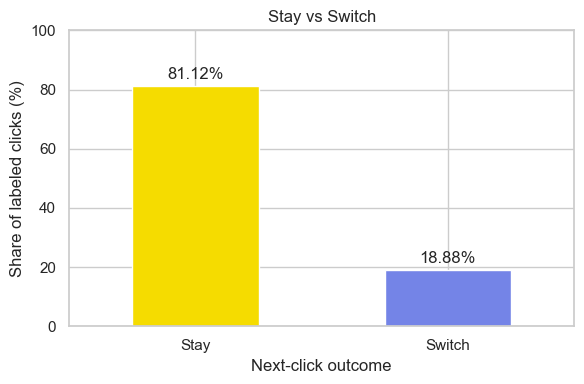

In [41]:
target_counts = train_df["switch_category"].value_counts().reindex([0, 1])
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Share (%)": 100 * target_counts / target_counts.sum()
}).rename(index={0: "Stay", 1: "Switch"})
display(target_summary.round(2))

ax = target_summary["Share (%)"].plot.bar(rot=0, color=["#F5DC00", "#7484E7"], figsize=(6, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
ax.set(title="Stay vs Switch", xlabel="Next-click outcome", ylabel="Share of labeled clicks (%)", ylim=(0, 100))
plt.tight_layout()
plt.show()

Switch represents 18.88% of training clicks. Always predicting Stay can therefore
look accurate while missing every switch. We need Switch precision, recall, and F1
to evaluate detection of the minority class.

### 5.2 Switch rate by current category

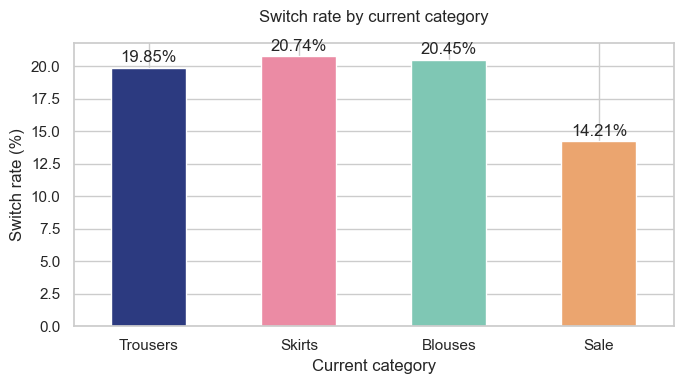

In [42]:
category_names = {1: "Trousers", 2: "Skirts", 3: "Blouses", 4: "Sale"}
category_rates = train_df.groupby("page 1 (main category)")["switch_category"].agg(
    ["size", "mean"]
).rename(index=category_names, columns={"size": "Clicks", "mean": "Switch rate"})
ax = (100 * category_rates["Switch rate"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate by current category", pad=15)
ax.set(xlabel="Current category", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Sale has a switch rate of 14.21%,
compared with 20.74% for Skirts. This variation supports
retaining current category. It describes an association, not an effect caused by the category.

### 5.3 Switch rate by browsing position

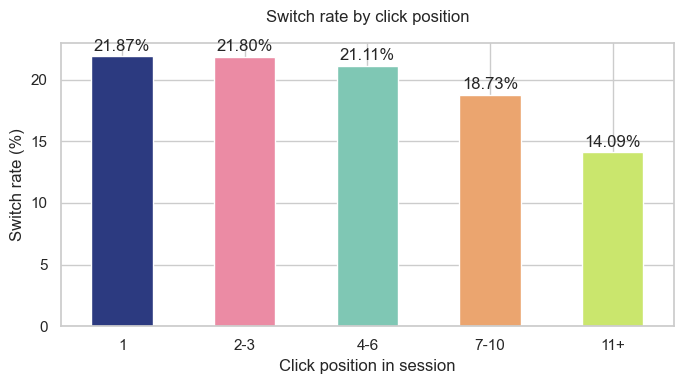

In [43]:
order_groups = pd.cut(
    train_df["order"], bins=[0, 1, 3, 6, 10, np.inf],
    labels=["1", "2-3", "4-6", "7-10", "11+"]
)
order_rates = train_df.groupby(order_groups, observed=True)["switch_category"].agg(
    ["size", "mean"]
)
ax = (100 * order_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F", "#CAE66D"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate by click position", pad=15)
ax.set(xlabel="Click position in session", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

The switch rate falls from 21.87% at the first click
to 14.09% at positions 11 and later. Retain `order` as current context.
This comparison also reflects which sessions continue long enough to reach later positions.

### 5.4 Switch rate by recent category consistency

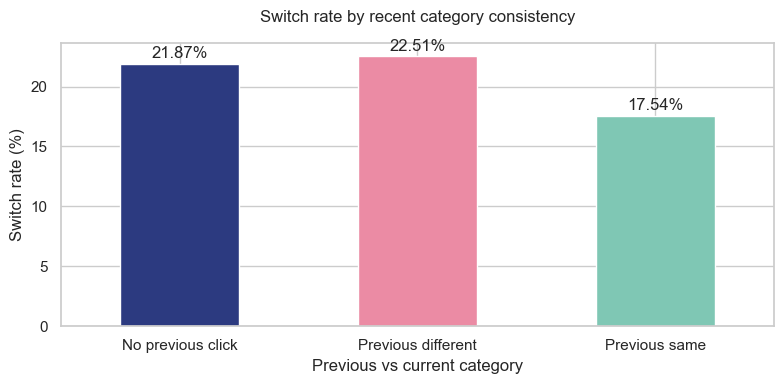

In [44]:
history_labels = {-1: "No previous click", 0: "Previous different", 1: "Previous same"}
consistency_rates = train_df.groupby("same_category_prev")["switch_category"].agg(
    ["size", "mean"]
).rename(index=history_labels)
ax = (100 * consistency_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4"], figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate by recent category consistency", pad=15)
ax.set(xlabel="Previous vs current category", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Switching is 22.51% after a different category, 17.54% after the same category, and
21.87% on first clicks. Recent consistency may help; the model comparison will test
whether it adds value beyond current information.

### 5.5 Switch rate by category visit count

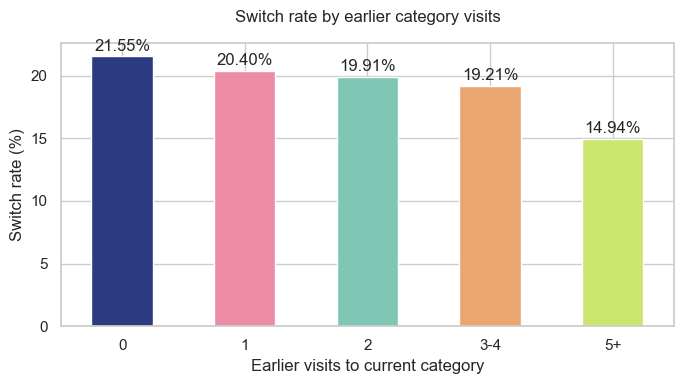

In [45]:
visit_groups = pd.cut(
    train_df["category_visit_count"], bins=[-1, 0, 1, 2, 4, np.inf],
    labels=["0", "1", "2", "3-4", "5+"]
)
visit_rates = train_df.groupby(visit_groups, observed=True)["switch_category"].agg(
    ["size", "mean"]
)
ax = (100 * visit_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F", "#CAE66D"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate by earlier category visits", pad=15)
ax.set(xlabel="Earlier visits to current category", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

Switching falls from 21.55% with no earlier category visit to 14.94% with five or more.
Repeated interest may help prediction, but it overlaps with session position.

### 5.6 Previous and current category

Current category,Trousers,Skirts,Blouses,Sale
Previous category,,,,
Trousers,24312,2102,2099,1282
Skirts,1297,17700,1997,1026
Blouses,1397,1106,18536,1724
Sale,1008,933,1011,19774


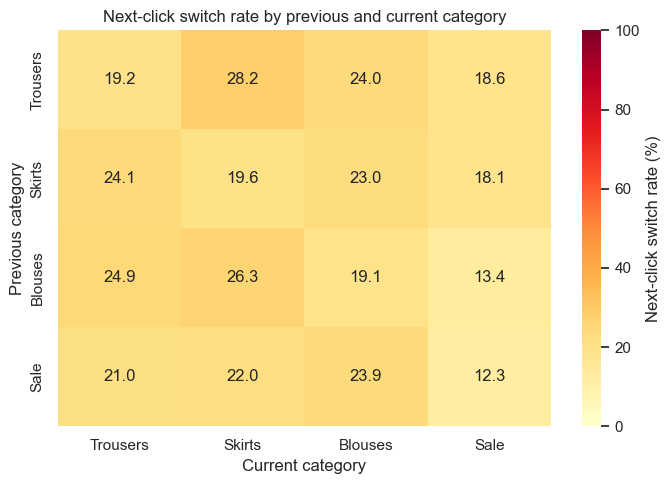

In [46]:
past_clicks = train_df[train_df["prev_category"] != 0]
transition_rates = past_clicks.pivot_table(
    index="prev_category", columns="page 1 (main category)",
    values="switch_category", aggfunc="mean"
).rename(index=category_names, columns=category_names)
transition_counts = past_clicks.pivot_table(
    index="prev_category", columns="page 1 (main category)",
    values="switch_category", aggfunc="size"
).rename(index=category_names, columns=category_names)
display(transition_counts.rename_axis(index="Previous category", columns="Current category"))
plt.figure(figsize=(7, 5))
sns.heatmap(100 * transition_rates, annot=True, fmt=".1f", cmap="YlOrRd",
            vmin=0, vmax=100, cbar_kws={"label": "Next-click switch rate (%)"})
plt.title("Next-click switch rate by previous and current category")
plt.xlabel("Current category")
plt.ylabel("Previous category")
plt.tight_layout()
plt.show()

For clicks with previous Trousers and current Skirts, 28.2% switch **on
the next click**. This is not the probability of moving from Trousers to Skirts.
First clicks are excluded; every displayed pair has at least 933 observations.

### 5.7 Price and switching

,median,mean
switch_category,,
Stay,43.0,43.65
Switch,43.0,44.25


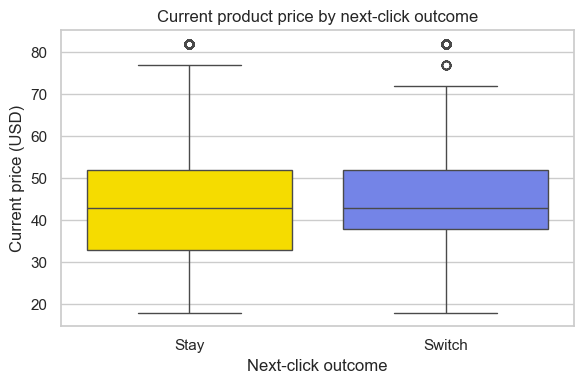

In [47]:
price_summary = train_df.groupby("switch_category")["price"].agg(["median", "mean"])
display(price_summary.rename(index={0: "Stay", 1: "Switch"}).round(2))
plt.figure(figsize=(6, 4))
sns.boxplot(data=train_df, x="switch_category", y="price", order=[0, 1], hue="switch_category", palette={0: "#F5DC00", 1: "#7484E7"}, saturation=1, legend=False)
plt.xticks([0, 1], ["Stay", "Switch"])
plt.title("Current product price by next-click outcome")
plt.xlabel("Next-click outcome")
plt.ylabel("Current price (USD)")
plt.tight_layout()
plt.show()

Both groups have a median price of $43, and their distributions overlap strongly.
Price alone does not clearly separate Stay and Switch. Keep it in the specified
current feature set to evaluate it alongside other inputs.

### 5.8 Catalogue page and switching

,Clicks,Switch rate
page,,
1,63833,0.178
2,28181,0.179
3,13014,0.219
4,5809,0.255
5,1654,0.282


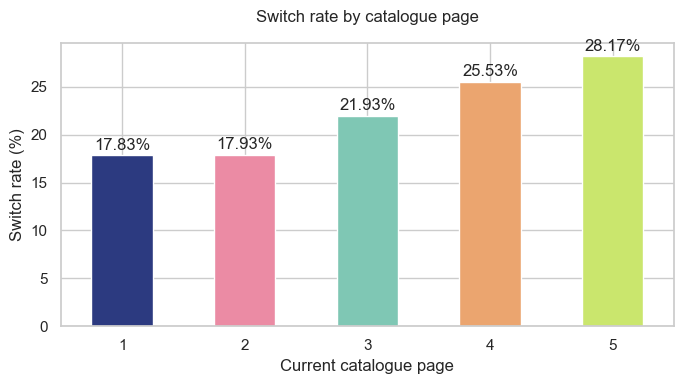

In [48]:
page_rates = train_df.groupby("page")["switch_category"].agg(["size", "mean"])
display(page_rates.rename(columns={"size": "Clicks", "mean": "Switch rate"}).round(3))
ax = (100 * page_rates["mean"]).plot.bar(rot=0, color = ["#2C3A80", "#EB8BA4", "#7FC7B4", "#EBA56F", "#CAE66D"], figsize=(7, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=2)
ax.set_title("Switch rate by catalogue page", pad=15)
ax.set(xlabel="Current catalogue page", ylabel="Switch rate (%)")
plt.tight_layout()
plt.show()

The switch rate rises from 17.83% on page 1 to
28.17% on page 5. Page 5 has only 1,654 observations,
compared with 63,833 on page 1. Retain catalogue page, while recognizing
that these pages may contain different categories and products.

### 5.9 Country
The IP-derived country code is unevenly represented. The table shows the ten
largest groups; the count below reports sparse groups.

In [49]:
def group_switch_summary(feature):
    summary = train_df.groupby(feature)["switch_category"].agg(["size", "mean"])
    summary = summary.rename(columns={"size": "Clicks", "mean": "Switch rate (%)"})
    summary["Share (%)"] = 100 * summary["Clicks"] / len(train_df)
    summary["Switch rate (%)"] *= 100
    return summary[["Clicks", "Share (%)", "Switch rate (%)"]]

country_summary = group_switch_summary("country").sort_values("Clicks", ascending=False)
display(country_summary.head(10).round(2))
print("Country groups:", len(country_summary))
print("Groups with fewer than 100 clicks:", (country_summary["Clicks"] < 100).sum())
print("Clicks in groups with fewer than 100:", country_summary.loc[country_summary["Clicks"] < 100, "Clicks"].sum())

,Clicks,Share (%),Switch rate (%)
country,,,
29,91157,81.03,19.18
9,12212,10.86,14.88
24,2837,2.52,19.84
46,1545,1.37,27.44
44,894,0.79,24.61
16,673,0.60,12.04
21,621,0.55,18.68
34,461,0.41,15.40
41,441,0.39,23.58


Country groups: 40
Groups with fewer than 100 clicks: 25
Clicks in groups with fewer than 100: 824


Country code 29 supplies 81.03% of training clicks; 25 of the 40
observed codes have fewer than 100 clicks each. **Exclude country** from this
browsing-behavior comparison and treat small-group rates cautiously.

### 5.10 Product and presentation attributes
These tables show the size and switch rate of each `colour`, `location`,
`model photography`, and `price 2` group.

In [50]:
colour_summary = group_switch_summary("colour").sort_values("Clicks", ascending=False)
location_summary = group_switch_summary("location").sort_values("Clicks", ascending=False)
photography_summary = group_switch_summary("model photography")
price2_summary = group_switch_summary("price 2")

print("Colour")
display(colour_summary.round(2))
print("Location")
display(location_summary.round(2))
print("Model photography")
display(photography_summary.round(2))
print("Price 2")
display(price2_summary.round(2))

Colour


,Clicks,Share (%),Switch rate (%)
colour,,,
2,20313,18.06,17.87
3,20129,17.89,17.05
6,11604,10.32,23.66
4,11274,10.02,17.34
14,10703,9.51,20.31
9,9198,8.18,17.45
12,6003,5.34,17.44
1,5447,4.84,17.55
7,4639,4.12,19.59


Location


,Clicks,Share (%),Switch rate (%)
location,,,
1,23623,21.00,18.95
2,22333,19.85,21.60
5,18959,16.85,18.60
4,18737,16.66,16.55
3,14788,13.15,16.92
6,14051,12.49,19.95


Model photography


,Clicks,Share (%),Switch rate (%)
model photography,,,
1,83592,74.31,18.50
2,28899,25.69,19.96


Price 2


,Clicks,Share (%),Switch rate (%)
price 2,,,
1,57401,51.03,19.01
2,55090,48.97,18.74


Colour rates range from 11.01% to 31.30%, but category and
product choice may confound the pattern. Location rates range from 16.55% to
21.60%. Front-view and profile-view photography differ only slightly (18.50%
versus 19.96%). **Keep** these three current-product attributes for joint
validation; these tables cannot establish independent predictive value.

`price 2` has two similarly sized groups and close switch rates (19.01% and
18.74%). **Exclude it** from the compact comparison; its extra predictive
value has not been tested.

### 5.11 Numeric correlation and group sizes
Check the four numeric inputs and the most uneven sample sizes. Category codes
are not treated as continuous numbers in the correlation table.

In [51]:
numeric_features = ["order", "price", "page", "category_visit_count"]
display(train_df[numeric_features].corr().round(3))

size_audit = pd.DataFrame({
    name: {"Smallest group": counts.min(), "Largest group": counts.max()}
    for name, counts in {
        "Country": train_df.groupby("country").size(),
        "Colour": train_df.groupby("colour").size(),
        "Catalogue page": train_df.groupby("page").size(),
    }.items()
}).T
display(size_audit)

,order,price,page,category_visit_count
order,1.000,-0.069,0.218,0.745
price,-0.069,1.000,-0.155,-0.045
page,0.218,-0.155,1.000,0.268
category_visit_count,0.745,-0.045,0.268,1.000


,Smallest group,Largest group
Country,1,91157
Colour,1080,20313
Catalogue page,1654,63833


`order` and `category_visit_count` correlate most strongly (Pearson
**0.745**): later clicks allow more earlier category visits. They describe
different behavior, so correlation alone does not decide whether to keep
either feature. Country has one-click groups and catalogue page ranges from
1,654 to 63,833 clicks. Group rates describe related clicks, not independent
shoppers, and small-group rates need caution.

## 6. Feature selection and availability

Predict just after the current click is recorded. The seven **Current** inputs
describe that click; **Current + History** adds information from the current
and earlier clicks. Both experiments use the same labeled rows and session
split. The offline data do not establish live logging latency.

| Feature set | Inputs | Available at prediction time |
| --- | --- | --- |
| Current | `page 1 (main category)`, `order`, `price`, `colour`, `location`, `model photography`, `page` | Recorded for the current click |
| Current + History | All Current inputs, plus `prev_category`, `same_category_prev`, `category_visit_count` | Previous clicks and current category are known; visit count excludes the current click |

### Feature decisions
This is a compact feature-set design for the research question, not a ranking
of individual feature importance. EDA does not prove that `colour` predicts
better than `country`; added value needs validation.

| Feature | Decision | Reason |
| --- | --- | --- |
| `page 1 (main category)` | Keep, Current | Defines the current state; four reasonably sized groups have different switch rates. |
| `order` | Keep, Current | Available click position; rates vary by position. Correlation with visit count is not a selection rule. |
| `price` | Keep, Current | Available product attribute; overlapping Stay/Switch distributions warrant joint testing. |
| `colour` | Keep, Current | Available product attribute; all 14 groups have at least 1,080 training clicks. |
| `location` | Keep, Current | Available photo placement; six reasonably sized groups. |
| `model photography` | Keep, Current | Available photo style; both groups are represented despite a small rate difference. |
| `page` | Keep, Current | Available catalogue context; rates vary, with a smaller page-5 group. |
| `prev_category` | Keep, History | Previous click is known and records the earlier category; first clicks use code 0. |
| `same_category_prev` | Keep, History | Direct same/different representation may help a linear model, though it can be derived from previous and current category; first clicks use code -1. |
| `category_visit_count` | Keep, History | Strictly prior visits to the current category capture repeat interest. |
| `country` | Exclude | Outside the browsing-behavior question; code 29 supplies 81.03% of training clicks and many groups are sparse. |
| `page 2 (clothing model)` | Exclude | 217 product codes add high-cardinality identity outside the compact Current set. |
| `price 2` | Exclude | Category-relative price is outside the compact Current set; its groups have close switch rates, but extra predictive value remains untested. |
| `year` | Exclude | Constant at 2008. |
| `month`, `day` | Exclude | Calendar effects are outside this behavioral question and need separate temporal evaluation. |
| `session ID` | Exclude | Group and split identifier, not a transferable predictor. |
| `next_category` | Exclude | Future information used only to create the label. |
| `switch_category` | Target | The answer being predicted, never an input. |

No feature is selected solely by correlation, and no input uses the next or
later click. Independent predictive value remains a validation question.

In [52]:
current_features = [
    "page 1 (main category)", "order", "price", "colour",
    "location", "model photography", "page"
]
current_history_features = current_features + [
    "prev_category", "same_category_prev", "category_visit_count"
]

current_categorical = [
    "page 1 (main category)", "colour", "location", "model photography"
]
current_numerical = ["order", "price", "page"]
history_categorical = current_categorical + ["prev_category", "same_category_prev"]
history_numerical = current_numerical + ["category_visit_count"]

Treat category codes as categories, including the three states of
`same_category_prev`. Treat `order`, `price`, `page`, and the visit count as
numerical. The visit count is strictly prior history: a first visit to the
current category has count 0. The table above records the reason for every
included or excluded dataset column and engineered feature.

In [53]:
X_train_current = train_df[current_features]
X_test_current = test_df[current_features]
X_train_history = train_df[current_history_features]
X_test_history = test_df[current_history_features]
y_train = train_df["switch_category"]
y_test = test_df["switch_category"]

print("Current features:", len(current_features))
print("Current + history features:", len(current_history_features))

# Target distribution in train and test sets
target_distribution = pd.DataFrame({
    "Train Count": y_train.value_counts().reindex([0, 1], fill_value=0),
    "Train (%)": y_train.value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100,
    "Test Count": y_test.value_counts().reindex([0, 1], fill_value=0),
    "Test (%)": y_test.value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
})

target_distribution.index = ["Stay (0)", "Switch (1)"]

display(target_distribution.round(2))

Current features: 7
Current + history features: 10


,Train Count,Train (%),Test Count,Test (%)
Stay (0),91257,81.12,23666,81.73
Switch (1),21234,18.88,5291,18.27


In [54]:
print(X_train_current.shape)
print(X_test_current.shape)
print(X_train_history.shape)
print(X_test_history.shape)
print(y_train.shape)
print(y_test.shape)

(112491, 7)
(28957, 7)
(112491, 10)
(28957, 10)
(112491,)
(28957,)


## 7. Model Development
All model comparisons, class weighting, hyperparameter selection, history ablation,
and threshold selection below use **training data only**. The session holdout from
Section 4 remains unchanged. Switch (1) F1 is the selection objective; precision,
recall, accuracy, macro F1 and ROC-AUC provide context. Test is used once in Section 12.

### 7.1 Shared GroupKFold and leakage checks
The same five session-disjoint folds are reused for every candidate and feature set.
History uses only earlier clicks; session IDs and next-click information are never inputs.

In [55]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

RANDOM_STATE = 42

# Session groups for group-aware cross-validation
groups = train_df["session ID"].to_numpy()

# 5-fold CV: sessions are kept together  (1/5 làm vadiation (20%), 4/5 làm training (80%))
group_cv = GroupKFold(n_splits=5)
folds = list(group_cv.split(X_train_history, y_train, groups))

In [56]:
excluded_cols = {"session ID", "next_category", "switch_category"}

assert excluded_cols.isdisjoint(X_train_current.columns)
assert excluded_cols.isdisjoint(X_train_history.columns)

print("Feature leakage check passed.")

Feature leakage check passed.


In [57]:
# Kiểm tra session overlap trong từng fold
for fold, (train_idx, val_idx) in enumerate(folds, 1):
    train_sessions = set(groups[train_idx])
    val_sessions = set(groups[val_idx])

    overlap = train_sessions & val_sessions
    assert len(overlap) == 0

    print(
        f"Fold {fold}: "
        f"{len(train_sessions)} train sessions, "
        f"{len(val_sessions)} validation sessions, "
        f"overlap = {len(overlap)}"
    )

Fold 1: 12149 train sessions, 3038 validation sessions, overlap = 0
Fold 2: 12150 train sessions, 3037 validation sessions, overlap = 0
Fold 3: 12150 train sessions, 3037 validation sessions, overlap = 0
Fold 4: 12150 train sessions, 3037 validation sessions, overlap = 0
Fold 5: 12149 train sessions, 3038 validation sessions, overlap = 0


In [58]:
scoring = {
    "Switch Precision": make_scorer(
        precision_score, pos_label=1, zero_division=0
    ),
    "Switch Recall": make_scorer(
        recall_score, pos_label=1, zero_division=0
    ),
    "Switch F1": make_scorer(
        f1_score, pos_label=1, zero_division=0
    ),
    "Macro F1": make_scorer(
        f1_score, average="macro", zero_division=0
    ),
    "Accuracy": "accuracy",
    "ROC-AUC": "roc_auc"
}

### 7.2 Alway-stay baseline


In [59]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

always_stay = DummyClassifier( strategy="constant",constant=0)

cv_stay = cross_validate(
    always_stay,
    X_train_current,
    y_train,
    groups=groups,
    cv=folds,
    scoring=scoring
)

stay_result = {
    "Model": "Always-Stay",
    "Switch Precision": cv_stay["test_Switch Precision"].mean(),
    "Switch Recall": cv_stay["test_Switch Recall"].mean(),
    "Switch F1": cv_stay["test_Switch F1"].mean(),
    "Macro F1": cv_stay["test_Macro F1"].mean(),
    "Accuracy": cv_stay["test_Accuracy"].mean()
}

display(pd.DataFrame([stay_result]).round(4))

,Model,Switch Precision,Switch Recall,Switch F1,Macro F1,Accuracy
0,Always-Stay,0.0,0.0,0.0,0.4479,0.8112


### 7.3 Preprocessing inside each fold
All preprocessing steps are included inside the model pipelines. Numerical variables are standardized for linear models, while categorical variables are one-hot encoded. Tree-based models keep numerical variables unchanged. During cross-validation, preprocessing is fitted separately on each training fold, preventing information from the validation fold from leaking into model training.

To avoid data leakage, `StandardScaler` and `OneHotEncoder` are **not fitted on the full training set before cross-validation**.

1. All preprocessing steps are placed **inside the `Pipeline`**.
2. For each fold, the preprocessing is fitted only on that fold's training data.
3. The fitted preprocessing is then used to transform the corresponding validation fold.

This ensures that information from the validation fold is not used during preprocessing or model training.

In [60]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

linear_current = ColumnTransformer([
    ("num", StandardScaler(), current_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), current_categorical)
])

linear_history = ColumnTransformer([
    ("num", StandardScaler(), history_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), history_categorical)
])

tree_current = ColumnTransformer([
    ("num", "passthrough", current_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), current_categorical)
])

tree_history = ColumnTransformer([
    ("num", "passthrough", history_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), history_categorical)
])

In [61]:
rf_params = {
    "n_estimators": 200,
    "max_depth": 12,
    "min_samples_split": 10,
    "min_samples_leaf": 5,
    "max_features": "sqrt",
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

logreg_params = {
    "C": 1.0,
    "solver": "lbfgs",
    "max_iter": 1000,
    "random_state": RANDOM_STATE
}

dt_params = {
    "max_depth": 6,
    "min_samples_split": 10,
    "min_samples_leaf": 5,
    "criterion": "gini",
    "random_state": RANDOM_STATE
}

svm_params = {
    "C": 1.0,
    "loss": "squared_hinge",
    "tol": 1e-3,
    "max_iter": 10000,
    "random_state": RANDOM_STATE
}

In [62]:
logreg = Pipeline([
    ("preprocessor", linear_current),
    ("model", LogisticRegression(
        class_weight="balanced",
        **logreg_params
    ))
])


decision_tree = Pipeline([
    ("preprocessor", tree_current),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        **dt_params
    ))
])

random_forest = Pipeline([
    ("preprocessor", tree_current),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        **rf_params
    ))
])

linear_svm = Pipeline([
    ("preprocessor", linear_current),
    ("model", LinearSVC(
        class_weight="balanced",
        **svm_params
    ))
])

logreg_normal = Pipeline([
    ("preprocessor", linear_current),
    ("model", LogisticRegression(
        class_weight=None,
        **logreg_params
    ))
])

rf_normal = Pipeline([
    ("preprocessor", tree_current),
    ("model", RandomForestClassifier(
        class_weight=None,
        **rf_params
    ))
])

logreg_history = Pipeline([
    ("preprocessor", linear_history),
    ("model", LogisticRegression(
        class_weight="balanced",
        **logreg_params
    ))
])

decision_tree_history = Pipeline([
    ("preprocessor", tree_history),
    ("model", DecisionTreeClassifier(
        class_weight="balanced",
        **dt_params
    ))
])

random_forest_history = Pipeline([
    ("preprocessor", tree_history),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        **rf_params
    ))
])

linear_svm_history = Pipeline([
    ("preprocessor", linear_history),
    ("model", LinearSVC(
        class_weight="balanced",
        **svm_params
    ))
])

logreg_history_normal = Pipeline([
    ("preprocessor", linear_history),
    ("model", LogisticRegression(
        class_weight=None,
        **logreg_params
    ))
])

rf_history_normal = Pipeline([
    ("preprocessor", tree_history),
    ("model", RandomForestClassifier(
        class_weight=None,
        **rf_params
    ))
])

In [63]:
models_to_check = {
    "Logistic Normal - Current": logreg_normal,
    "Logistic Balanced - Current": logreg,
    "Decision Tree Balanced - Current": decision_tree,
    "Random Forest Normal - Current": rf_normal,
    "Random Forest Balanced - Current": random_forest,
    "Linear SVM Balanced - Current": linear_svm,

    "Logistic Normal - History": logreg_history_normal,
    "Logistic Balanced - History": logreg_history,
    "Decision Tree Balanced - History": decision_tree_history,
    "Random Forest Normal - History": rf_history_normal,
    "Random Forest Balanced - History": random_forest_history,
    "Linear SVM Balanced - History": linear_svm_history
}

for name, model in models_to_check.items():
    assert "preprocessor" in model.named_steps
    assert "model" in model.named_steps

print("All Current and History models use preprocessing inside Pipeline.")

All Current and History models use preprocessing inside Pipeline.


In [64]:
# Số features trước và sau khi preprocessing cho current features
linear_current.fit(X_train_current)
tree_current.fit(X_train_current)

print("Original Current features:", X_train_current.shape[1])

print(
    "After linear preprocessing:",
    len(linear_current.get_feature_names_out())
)

print(
    "After tree preprocessing:",
    len(tree_current.get_feature_names_out())
)




Original Current features: 7
After linear preprocessing: 29
After tree preprocessing: 29


In [65]:
# Số features trước và sau khi preprocessing cho current + history features
linear_history.fit(X_train_history)
tree_history.fit(X_train_history)

print("Original Current + History features:", X_train_history.shape[1])

print(
    "After linear preprocessing:",
    len(linear_history.get_feature_names_out())
)

print(
    "After tree preprocessing:",
    len(tree_history.get_feature_names_out())
)

Original Current + History features: 10
After linear preprocessing: 38
After tree preprocessing: 38


### 7.4 Comparing LR & RF normal with LR & RF balanced

In [66]:
imbalance_models = {
    "Current": {
        "X": X_train_current,
        "models": {
            "Logistic Normal": logreg_normal,
            "Logistic Balanced": logreg,
          
        }
    },

    "Current + History": {
        "X": X_train_history,
        "models": {
            "Logistic Normal": logreg_history_normal,
            "Logistic Balanced": logreg_history,
       
        }
    }
}

imbalance_results = []

for feature_set, config in imbalance_models.items():
    X = config["X"]

    for name, model in config["models"].items():
        cv = cross_validate(
            model,
            X,
            y_train,
            groups=groups,
            cv=folds,
            scoring=scoring
        )

        imbalance_results.append({
            "Feature Set": feature_set,
            "Model": name,
            "Switch Precision": cv["test_Switch Precision"].mean(),
            "Switch Recall": cv["test_Switch Recall"].mean(),
            "Switch F1": cv["test_Switch F1"].mean(),
            "Macro F1": cv["test_Macro F1"].mean(),
            "Accuracy": cv["test_Accuracy"].mean(),
            "ROC-AUC": cv["test_ROC-AUC"].mean()
        })

imbalance_results = pd.DataFrame(imbalance_results)

display(imbalance_results.round(4))

,Feature Set,Model,Switch Precision,Switch Recall,Switch F1,Macro F1,Accuracy,ROC-AUC
0,Current,Logistic Normal,0.0000,0.0000,0.0000,0.4479,0.8112,0.6113
1,Current,Logistic Balanced,0.2356,0.5977,0.3380,0.5030,0.5579,0.6115
2,Current + History,Logistic Normal,0.4691,0.0009,0.0019,0.4488,0.8112,0.6213
3,Current + History,Logistic Balanced,0.2406,0.6162,0.3461,0.5075,0.5604,0.6216


**Interpretation:**  
Balancing clearly improves both models. For Logistic Regression, Switch F1 rises from **0.000 to 0.338** and Recall from **0.000 to 0.5977**. For Random Forest, Switch F1 rises from **0.091 to 0.342** and Recall from **0.0529 to 0.5443**. Although Accuracy decreases, the balanced versions are much better at detecting the minority Switch class.

## 8. Model comparison on training folds


In [67]:
models_history = {
    "Logistic Regression": logreg_history,
    "Decision Tree": decision_tree_history,
    "Random Forest": random_forest_history,
    "Linear SVM": linear_svm_history
}

In [68]:
model_results = []

for name, model in models_history.items():
    cv = cross_validate(
        model,
        X_train_history,
        y_train,
        groups=groups,
        cv=folds,
        scoring=scoring
    )

    model_results.append({
        "Model": name,
        "CV Switch F1 Mean": cv["test_Switch F1"].mean(),
        "CV Switch F1 Std": cv["test_Switch F1"].std(),
        "CV Precision Mean": cv["test_Switch Precision"].mean(),
        "CV Recall Mean": cv["test_Switch Recall"].mean(),
        "CV Macro F1 Mean": cv["test_Macro F1"].mean(),
        "CV ROC-AUC Mean": cv["test_ROC-AUC"].mean()
    })

model_results = pd.DataFrame(model_results).sort_values(
    "CV Switch F1 Mean",
    ascending=False
)

display(model_results.round(4))

,Model,CV Switch F1 Mean,CV Switch F1 Std,CV Precision Mean,CV Recall Mean,CV Macro F1 Mean,CV ROC-AUC Mean
2,Random Forest,0.3693,0.0098,0.2671,0.5987,0.5456,0.6535
3,Linear SVM,0.3462,0.0070,0.2407,0.6162,0.5076,0.6214
0,Logistic Regression,0.3461,0.0070,0.2406,0.6162,0.5075,0.6216
1,Decision Tree,0.3432,0.0094,0.2378,0.6422,0.4910,0.6196


In [69]:
best_model_name = model_results.iloc[0]["Model"]

print("Selected model:", best_model_name)
print(
    "Mean CV Switch F1:",
    round(model_results.iloc[0]["CV Switch F1 Mean"], 4)
)

Selected model: Random Forest
Mean CV Switch F1: 0.3693


## 9. Tune only the strongest candidate


### 9.1 Tuning Hyperparameters

In [70]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, f1_score
import pandas as pd

# Reuse the Group CV from model comparison
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

param_distributions = {
    "n_estimators": [200, 400, 600],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"]
}

switch_f1 = make_scorer(
    f1_score,
    pos_label=1,
    zero_division=0
)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=40,
    scoring=switch_f1,
    cv=folds,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1,
    refit=True,
    return_train_score=True
)

random_search.fit(
    X_train_history,
    y_train
)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV Switch F1:")
print(round(random_search.best_score_, 4))

best_rf = random_search.best_estimator_


Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters:
{'n_estimators': 400, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 10, 'class_weight': 'balanced'}

Best CV Switch F1:
0.3697


**Tuning result:**  
Random Forest achieves a best CV Switch F1 of **0.3697** using 400 trees, `max_depth=10`, `min_samples_split=5`, `min_samples_leaf=4`, `max_features="log2"`, and balanced class weights. The improvement is modest but confirms that this configuration performs better under cross-validation.

### 9.2 Out-of-fold scores and threshold tuning


In [89]:
tuned_rf = Pipeline([
    ("preprocessor", tree_history),
    ("model", clone(random_search.best_estimator_))
])

In [90]:
from sklearn.model_selection import cross_val_predict

oof_prob_rf = cross_val_predict(
    tuned_rf,
    X_train_history,
    y_train,
    groups=groups,
    cv=folds,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [92]:
thresholds = np.arange(0.10, 0.81, 0.01)

threshold_results_rf = []

for threshold in thresholds:
    pred = (oof_prob_rf >= threshold).astype(int)

    threshold_results_rf.append({
        "Threshold": threshold,
        "Switch Precision": precision_score(
            y_train, pred, pos_label=1, zero_division=0
        ),
        "Switch Recall": recall_score(
            y_train, pred, pos_label=1, zero_division=0
        ),
        "Switch F1": f1_score(
            y_train, pred, pos_label=1, zero_division=0
        )
    })

threshold_results_rf = pd.DataFrame(threshold_results_rf)


best_row_rf = threshold_results_rf.loc[
    threshold_results_rf["Switch F1"].idxmax()
]

best_threshold_rf = best_row_rf["Threshold"]

print(f"Best threshold: {best_threshold_rf:.2f}")
print(f"OOF Precision: {best_row_rf['Switch Precision']:.4f}")
print(f"OOF Recall: {best_row_rf['Switch Recall']:.4f}")
print(f"OOF Switch F1: {best_row_rf['Switch F1']:.4f}")

Best threshold: 0.49
OOF Precision: 0.2555
OOF Recall: 0.6657
OOF Switch F1: 0.3693


**Threshold tuning result:**  
The tuned Random Forest achieves a mean CV Switch F1 of **0.3697** during hyperparameter tuning. Using OOF predictions, the best threshold is **0.49**, producing an OOF Switch F1 of **0.3693**. The small difference is expected because the CV score is the average F1 across folds, while the OOF score is calculated once on all combined out-of-fold predictions. Overall, threshold tuning provides almost no additional improvement over the default decision rule.

### 9.3 Historical feature ablation

In [86]:
from itertools import combinations
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

# Best tuned Random Forest
best_rf_model = clone(random_search.best_estimator_)

# Historical features to test
history_features = [
    "prev_category",
    "same_category_prev",
    "category_visit_count"
]

# All combinations: none, single, pairs, all three
feature_groups = [()]
for r in range(1, len(history_features) + 1):
    feature_groups += list(combinations(history_features, r))

ablation_results = []

for added_features in feature_groups:

    # Current features + selected historical features
    selected_features = current_features + list(added_features)

    categorical = current_categorical.copy()
    numerical = current_numerical.copy()

    if "prev_category" in added_features:
        categorical.append("prev_category")

    if "same_category_prev" in added_features:
        categorical.append("same_category_prev")

    if "category_visit_count" in added_features:
        numerical.append("category_visit_count")

    # Preprocessing for Random Forest
    preprocessor = ColumnTransformer([
        ("num", "passthrough", numerical),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
    ])

    # Same best RF, only feature set changes
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", clone(best_rf_model))
    ])

    X = train_df[selected_features]

    # OOF probabilities using the same GroupKFold folds
    oof_prob = cross_val_predict(
        model,
        X,
        y_train,
        groups=groups,
        cv=folds,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Fixed threshold selected earlier
    pred = (oof_prob >= 0.49).astype(int)

    ablation_results.append({
        "Added History": (
            "None" if len(added_features) == 0
            else " + ".join(added_features)
        ),
        "Switch Precision": precision_score(
            y_train, pred, pos_label=1, zero_division=0
        ),
        "Switch Recall": recall_score(
            y_train, pred, pos_label=1, zero_division=0
        ),
        "Switch F1": f1_score(
            y_train, pred, pos_label=1, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_train, oof_prob)
    })

ablation_results = pd.DataFrame(ablation_results)

ablation_results = ablation_results.sort_values(
    "Switch F1",
    ascending=False
).reset_index(drop=True)

display(ablation_results.round(4))

,Added History,Switch Precision,Switch Recall,Switch F1,ROC-AUC
0,prev_category + category_visit_count,0.2555,0.6705,0.3700,0.6511
1,same_category_prev + category_visit_count,0.2572,0.6585,0.3699,0.6520
2,prev_category + same_category_prev + category_...,0.2555,0.6657,0.3693,0.6524
3,category_visit_count,0.2554,0.6645,0.3690,0.6496
4,same_category_prev,0.2577,0.6426,0.3679,0.6485
5,prev_category + same_category_prev,0.2558,0.6503,0.3671,0.6485
6,prev_category,0.2545,0.6557,0.3667,0.6474
7,None,0.2517,0.6505,0.3630,0.6434


In [88]:
best_ablation = ablation_results.iloc[0]

print("Best feature combination:", best_ablation["Added History"])
print(f"Best OOF Switch F1: {best_ablation['Switch F1']:.4f}")

Best feature combination: prev_category + category_visit_count
Best OOF Switch F1: 0.3700


**Ablation result:**  
Historical features improve the tuned Random Forest compared with using current-click features only. The best subset is **`prev_category + category_visit_count`**, achieving a Switch F1 of **0.3700**, compared with **0.3630** for Current-only features.

Adding all three historical features gives a very similar Switch F1 of **0.3693**, so the third feature does not provide additional benefit in this setting. Overall, the ablation suggests that browsing history is useful, especially information about the **previous category** and **how often the current category has already been visited**, although the improvement is modest.

### 9.4 Final model selection

The **tuned Random Forest** is selected as the final model because it achieves the strongest performance on the main evaluation metric, **Switch F1**.

The selected Random Forest uses the following hyperparameters:

- `n_estimators = 400`
- `max_depth = 10`
- `min_samples_split = 5`
- `min_samples_leaf = 4`
- `max_features = "log2"`
- `class_weight = "balanced"`
- `random_state = 42`

Feature ablation shows that the best feature set is:

- All **Current** features
- `prev_category`
- `category_visit_count`

This configuration achieves an OOF Switch F1 of approximately **0.3700**.

The final classification threshold is fixed at **0.49**.

Therefore, the final model is a tuned Random Forest with the selected feature subset and a threshold of **0.49**, which will be retrained on the full training set before the final evaluation on the untouched test set.

## 10. Final Model Training and Test Evaluation


### 10.1 Final evaluation

In [ ]:

final_features = current_features + [
    "prev_category",
    "category_visit_count"
]

final_categorical = current_categorical + [
    "prev_category"
]

final_numerical = current_numerical + [
    "category_visit_count"
]

final_preprocessor = ColumnTransformer([
    ("num", "passthrough", final_numerical),
    ("cat", OneHotEncoder(handle_unknown="ignore"), final_categorical)
])

final_rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=4,
    max_features="log2",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

final_model = Pipeline([
    ("preprocessor", final_preprocessor),
    ("model", final_rf)
])

In [94]:
X_train_final = train_df[final_features]
X_test_final = test_df[final_features]

final_model.fit(X_train_final, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [95]:
test_prob = final_model.predict_proba(X_test_final)[:, 1]

test_pred = (test_prob >= 0.49).astype(int)

In [ ]:
final_test_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Switch Precision",
        "Switch Recall",
        "Switch F1",
        "Macro F1",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, test_pred),
        precision_score(y_test, test_pred, pos_label=1, zero_division=0),
        recall_score(y_test, test_pred, pos_label=1, zero_division=0),
        f1_score(y_test, test_pred, pos_label=1, zero_division=0),
        f1_score(y_test, test_pred, average="macro", zero_division=0),
        roc_auc_score(y_test, test_prob)
    ]
})

display(final_test_results.round(4))

,Metric,Score
0,Accuracy,0.5718
1,Switch Precision,0.2500
2,Switch Recall,0.6719
3,Switch F1,0.3644
4,Macro F1,0.5208
5,ROC-AUC,0.6590


### 10.2 Confusion matrix

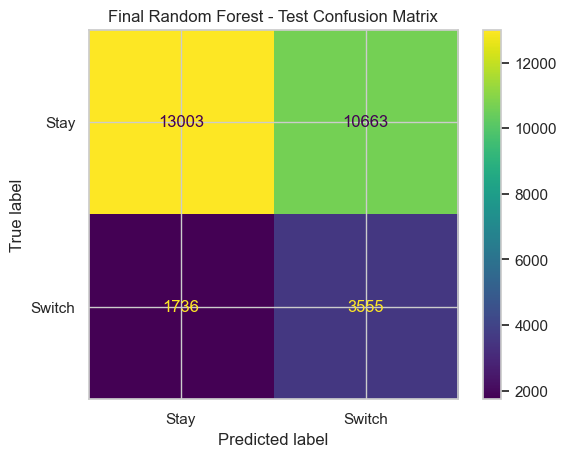

In [97]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["Stay", "Switch"]
)

plt.title("Final Random Forest - Test Confusion Matrix")
plt.show()

The model detects many actual Switch cases (**3,555 true positives**) but also produces a large number of false positives (**10,663**). This indicates relatively strong Switch recall but low Switch precision, which is expected because the model is designed to give more attention to the minority Switch class.

### 10.3 Classification Report

In [98]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    test_pred,
    target_names=["Stay", "Switch"],
    digits=4
))

              precision    recall  f1-score   support

        Stay     0.8822    0.5494    0.6772     23666
      Switch     0.2500    0.6719    0.3644      5291

    accuracy                         0.5718     28957
   macro avg     0.5661    0.6107    0.5208     28957
weighted avg     0.7667    0.5718    0.6200     28957



The final Random Forest achieves a **Switch recall of 0.6719**, meaning it identifies about 67% of actual switching cases. However, Switch precision is only **0.2500**, indicating many false positives. Overall accuracy is **0.5718**, while the Switch F1-score is **0.3644**, reflecting the trade-off between detecting more Switch cases and lower precision.

### 10.4 Feature Importance

In [101]:
feature_names = final_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = final_model.named_steps[
    "model"
].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

def get_original_feature(name):
    name = name.replace("num__", "").replace("cat__", "")

    for col in final_features:
        if name == col or name.startswith(col + "_"):
            return col

    return name


feature_importance["Original Feature"] = (
    feature_importance["Feature"]
    .apply(get_original_feature)
)

original_importance = (
    feature_importance
    .groupby("Original Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
)

display(original_importance.round(4))

,Original Feature,Importance
4,order,0.1984
5,page,0.1394
0,category_visit_count,0.1384
1,colour,0.1211
7,prev_category,0.1152
6,page 1 (main category),0.1064
8,price,0.0783
2,location,0.0743
3,model photography,0.0285


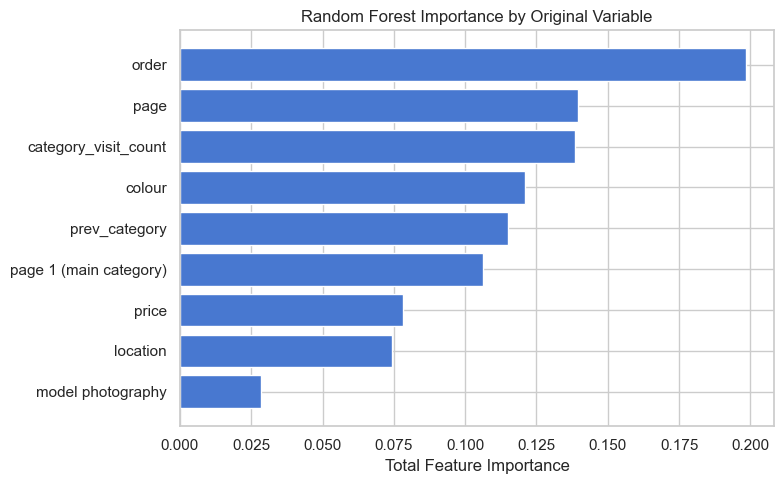

In [102]:
plot_data = original_importance.sort_values("Importance")

plt.figure(figsize=(8, 5))
plt.barh(
    plot_data["Original Feature"],
    plot_data["Importance"]
)

plt.xlabel("Total Feature Importance")
plt.title("Random Forest Importance by Original Variable")
plt.tight_layout()
plt.show()

**Feature importance result:**  
`order` is the most important predictor (**0.1984**), followed by `page` (**0.1394**) and `category_visit_count` (**0.1384**). Among the historical features, both `category_visit_count` and `prev_category` have relatively high importance, supporting the finding that browsing history adds useful predictive information. `model photography` contributes the least (**0.0285**).

These importance values indicate predictive contribution only and should not be interpreted as causal effects.

## 11. Research Question Answers

**RQ1: How well can current browsing information predict category switching?**  
Current browsing information provides a moderate level of predictive ability. Using only current-click features, the tuned Random Forest achieved an OOF Switch F1 of approximately **0.3630**. This shows that the current browsing context contains useful signals for predicting whether the next click will switch to another category, but the prediction remains challenging.

**RQ2: Does adding browsing history improve switch prediction?**  
Yes, but the improvement is modest. Adding historical features increased the best OOF Switch F1 from about **0.3630** to **0.3700**. The strongest historical combination was `prev_category` and `category_visit_count`, indicating that recent category movement and repeated visits to the current category add useful predictive information.

**Overall answer:**  
Yes, both current and historical browsing behavior can help predict category switching. Current-click information already provides useful predictive signals, while browsing history adds a small but measurable improvement.

## 12. Limitations
- The dataset contains clickstream information but does not include richer customer information such as demographics or long-term purchase history.
- `session ID` represents browsing sessions rather than persistent individual users, so behaviour cannot be reliably linked across sessions.
- Only a small set of historical features is used, so more complex sequential behaviour may not be fully captured.
- The Switch class is imbalanced, which makes it difficult to achieve both high precision and high recall.
- The final model still has relatively low Switch precision, meaning that many predicted Switch cases are false positives.
- The dataset comes from 2008, so browsing behaviour may differ from modern e-commerce platforms.
- Random Forest feature importance shows predictive contribution, not causal relationships.

## 13. Future work
- Add richer historical features, such as longer click sequences, transition patterns, and time spent within a category.
- Explore more advanced models that can better capture nonlinear or sequential browsing behaviour.
- Improve class-imbalance handling to increase Switch precision without losing too much recall.
- Evaluate the model on newer e-commerce datasets to check whether the findings generalize to modern browsing behaviour.
- Incorporate additional customer and transaction information, if available, such as purchase history or user-level attributes.
- Investigate whether sequence-based models can better predict when a user is likely to switch categories.


## 14. Conclusion

This study examined whether current and historical browsing behaviour can predict whether a user will switch to another product category on the next click.

The results show that current-click information already provides useful predictive signals, while adding browsing-history features gives a small but measurable improvement. The best historical combination was `prev_category` and `category_visit_count`.

The final model was a tuned **Random Forest** using the selected feature set and a classification threshold of **0.49**. On the final test set, the model achieved a **Switch F1-score of 0.3644** and a **Switch recall of 0.6719**, showing that it can identify a substantial proportion of actual switching cases, although precision remains relatively low.

Overall, the findings suggest that category switching is partially predictable from clickstream behaviour, but richer behavioural information and more advanced modelling may be needed to achieve stronger predictive performance.

### Dataset reference
Variable meanings follow the local `e-shop clothing 2008 data description.txt`.
Suggested citation: Łapczyński, M. and Białowąs, S. (2013),
*Discovering Patterns of Users' Behaviour in an E-shop – Comparison of Consumer Buying
Behaviours in Poland and Other European Countries*, Studia Ekonomiczne 151, 144–153.